In [247]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
%matplotlib inline

In [248]:
url_red = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'
df_red = pd.read_csv(url_red, sep=';')

url_white = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv'
df_white = pd.read_csv(url_white, sep=';')

df_red['is_red'] = 1
df_white['is_red'] = 0

print(f'{round(float(df.duplicated().sum() / df.shape[0]), 2) * 100} % дупликатов')


df = pd.concat([df_red, df_white], ignore_index=True)

df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

df.head()

0.0 % дупликатов
(5320, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,1


In [249]:
stats = df.describe().T[['mean', 'std', 'min', '50%', 'max']]
stats['skew'] = df.skew()
stats['kurtosis'] = df.kurtosis()
stats

,mean,std,min,50%,max,skew,kurtosis
fixed acidity,7.215179,1.319671,3.80000,7.00000,15.90000,1.650417,4.589079
volatile acidity,0.344130,0.168248,0.08000,0.30000,1.58000,1.504557,2.863175
citric acid,0.318494,0.147157,0.00000,0.31000,1.66000,0.484309,2.582471
residual sugar,5.048477,4.500180,0.60000,2.70000,65.80000,1.706550,7.025595
chlorides,0.056690,0.036863,0.00900,0.04700,0.61100,5.338237,48.260708
free sulfur dioxide,30.036654,17.805045,1.00000,28.00000,289.00000,1.362719,9.520706
total sulfur dioxide,114.109023,56.774223,6.00000,116.00000,440.00000,0.063614,-0.299997
density,0.994535,0.002966,0.98711,0.99465,1.03898,0.666326,8.711498
pH,3.224664,0.160379,2.72000,3.21000,4.01000,0.389969,0.431811
sulphates,0.533357,0.149743,0.22000,0.51000,2.00000,1.809454,8.612917


In [250]:
X = df.drop(columns=['quality'])
y = df['quality']

<Axes: xlabel='quality', ylabel='Count'>

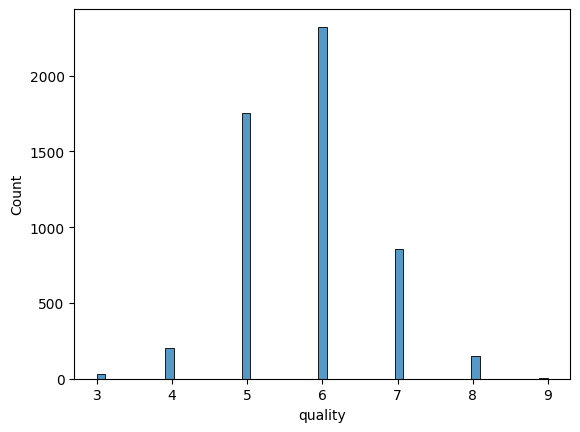

In [251]:
sns.histplot(y)

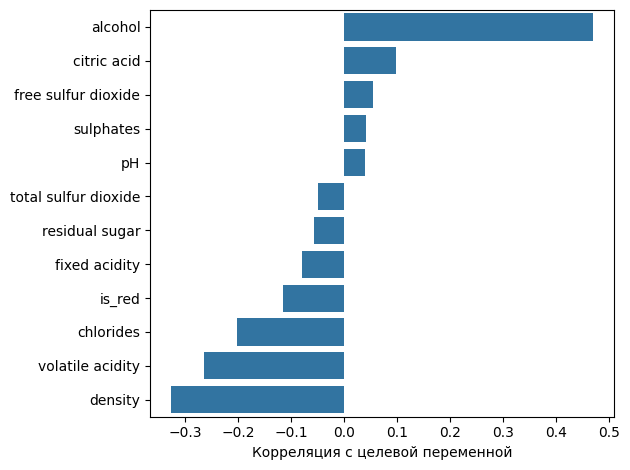

In [252]:
correlations = X.corrwith(y).sort_values(ascending=False)

plot = sns.barplot(y=correlations.index, x=correlations)

plot.set(xlabel="Корреляция с целевой переменной", ylabel="")

plt.tight_layout()
plt.show()

<Axes: >

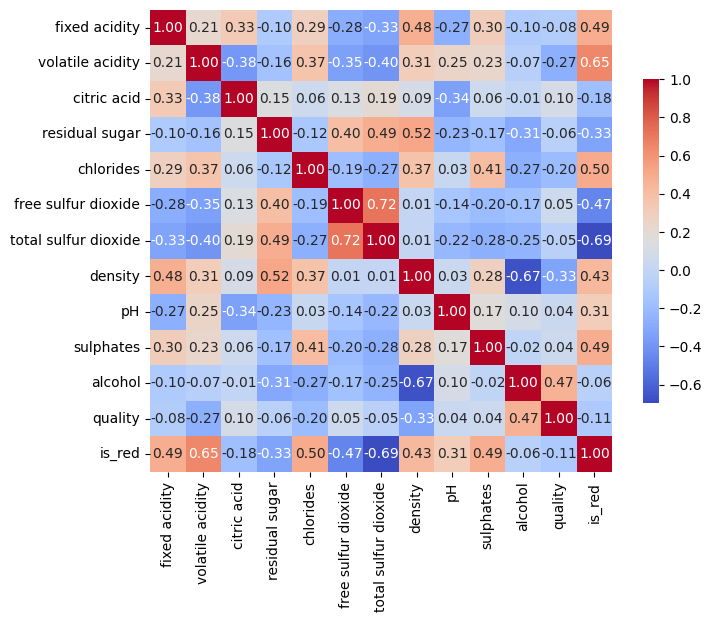

In [253]:
corr_matrix = df.corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True, cbar_kws={'shrink': 0.7})

In [254]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [255]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

models = {
    'Baseline': DummyRegressor(strategy='mean'),
    'LinearRegression': LinearRegression(),
    'RandomForestRegressor': RandomForestRegressor(random_state=42),
    'GradientBoostingRegressor': GradientBoostingRegressor(random_state=42)
}

rows = []
coefs = []

for name, model in models.items():
  model.fit(X_train_scaled, y_train)
  pred = model.predict(X_test_scaled)
  train_pred = model.predict(X_train_scaled)
  if hasattr(model, 'coef_'):
    coefs.append({'model': name, 'coef': model.coef_})
  elif hasattr(model, 'feature_importances_'):
    coefs.append({'model': name, 'coef': model.feature_importances_})
  rows.append({
      'model': name,
      'test RMSE': root_mean_squared_error(y_test, pred),
      'train RMSE': root_mean_squared_error(y_train, train_pred),
      'MAE': mean_absolute_error(y_test, pred),
  })

results = pd.DataFrame(rows).sort_values("test RMSE")
results




,model,test RMSE,train RMSE,MAE
2,RandomForestRegressor,0.665216,0.259215,0.508938
3,GradientBoostingRegressor,0.685423,0.642579,0.527942
1,LinearRegression,0.720792,0.732768,0.560200
0,Baseline,0.867579,0.882714,0.694226


In [256]:
def show_weights(features, weights, title, ax=None):
    if ax is None:
      fig, ax = plt.subplots(figsize=(8, 6))

    sorted_weights = sorted(zip(weights, features), reverse=True)
    weights = [x[0] for x in sorted_weights]
    features = [x[1] for x in sorted_weights]

    sns.barplot(y=features, x=weights, ax=ax)
    ax.set_xlabel("Weight")


    ax.set_title(title, fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel("Вес признака", fontsize=11)
    ax.set_ylabel("")
    ax.axvline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)
    ax.grid(axis='x', linestyle=':', alpha=0.6)
    sns.despine(ax=ax, left=False, bottom=False)

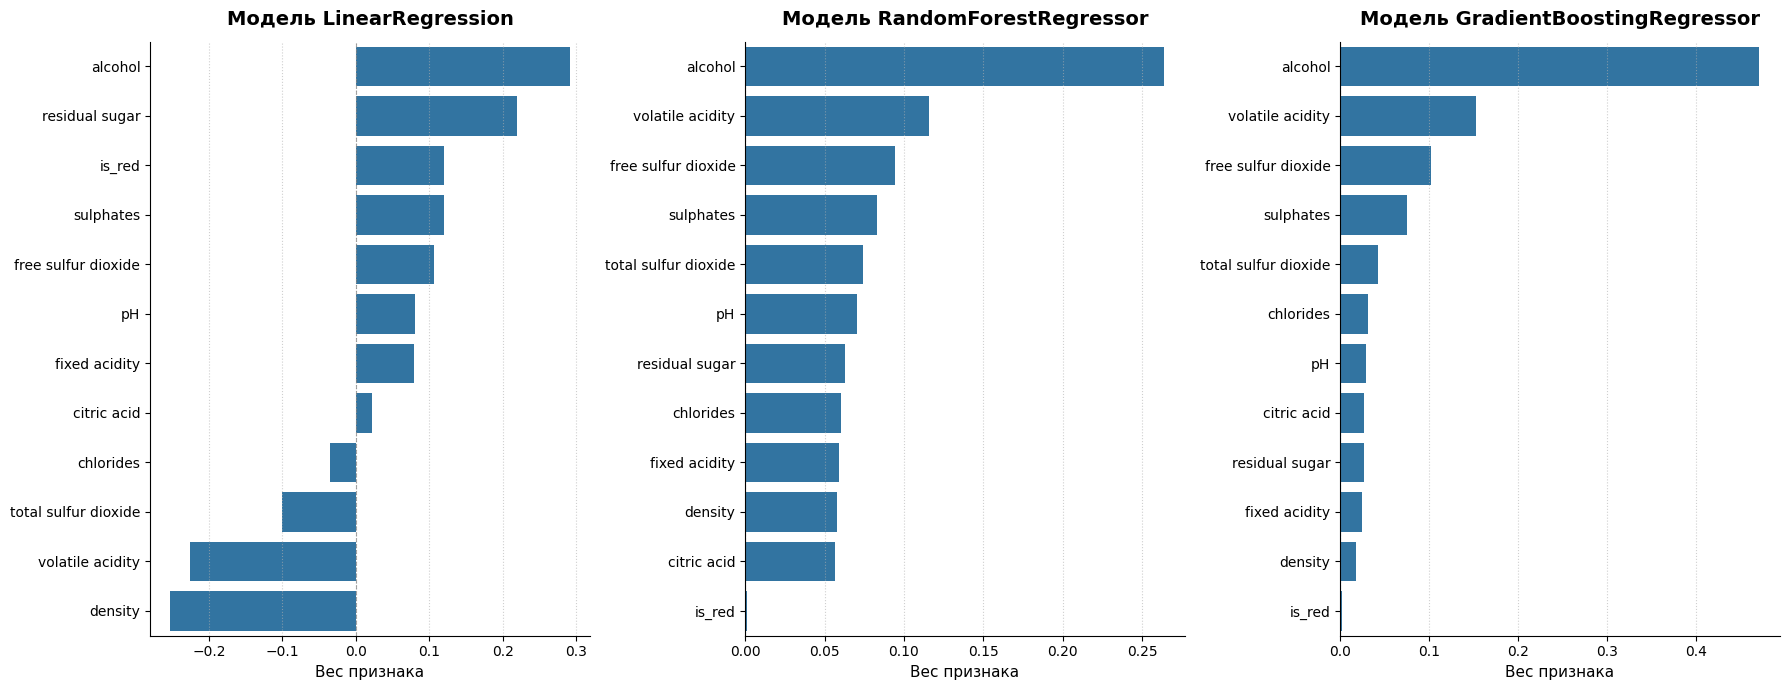

In [257]:
n_models = len(coefs)
fig, axes = plt.subplots(ncols=n_models, figsize=(6 * n_models, 7))


for ax, model_info in zip(axes, coefs):
  name = model_info['model']
  coef = model_info['coef']
  show_weights(X.columns, coef, f'Модель {name}', ax=ax)

plt.tight_layout()
plt.show()




<Axes: ylabel='Count'>

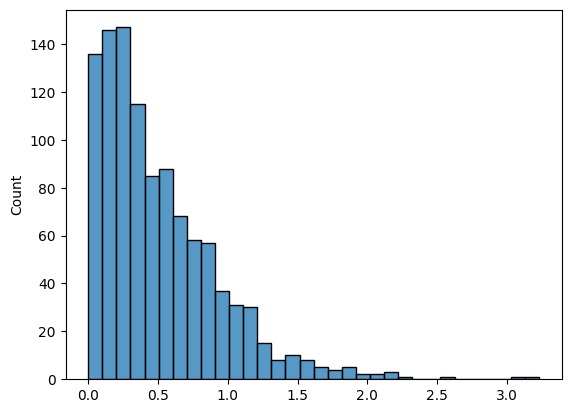

In [258]:
model = RandomForestRegressor(random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = pd.Series(model.predict(X_test_scaled), index=y_test.index)
error = (y_test - y_pred).abs()
sns.histplot(error)


In [259]:
df_results = pd.DataFrame({
    'y_true':y_test,
    'y_pred':y_pred.round(2),
    'error': error.round(2),
})

In [260]:
df_max = df_results.nlargest(20, 'error').reset_index()
df_max

,index,y_true,y_pred,error
0,4151,3,6.23,3.23
1,1729,3,6.10,3.10
2,4404,4,6.62,2.62
3,718,3,5.32,2.32
4,2077,8,5.80,2.20
5,2057,4,6.13,2.13
6,1253,3,5.12,2.12
7,3456,8,5.93,2.07
8,4423,4,6.02,2.02
9,4652,8,6.02,1.98


In [261]:
df_min = df_results.nsmallest(20, 'error').reset_index()
df_min

,index,y_true,y_pred,error
0,1658,7,7.00,0.00
1,553,5,5.00,0.00
2,4854,6,6.00,0.00
3,3765,6,6.00,0.00
4,748,6,6.00,0.00
5,1634,5,5.00,0.00
6,387,7,7.00,0.00
7,3168,6,6.00,0.00
8,367,5,5.00,0.00
9,51,5,5.00,0.00


In [262]:
max_idx = error.nlargest(n=5)
X_test.loc[max_idx.index]

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,is_red
4151,6.2,0.23,0.35,0.7,0.051,24.0,111.0,0.99160,3.37,0.43,11.0,0
1729,7.1,0.32,0.32,11.0,0.038,16.0,66.0,0.99370,3.24,0.40,11.5,0
4404,6.5,0.32,0.48,8.0,0.026,18.0,88.0,0.99144,3.22,0.79,12.7,0
718,10.4,0.44,0.42,1.5,0.145,34.0,48.0,0.99832,3.38,0.86,9.9,1
2077,8.1,0.27,0.35,1.7,0.030,38.0,103.0,0.99255,3.22,0.63,10.4,0


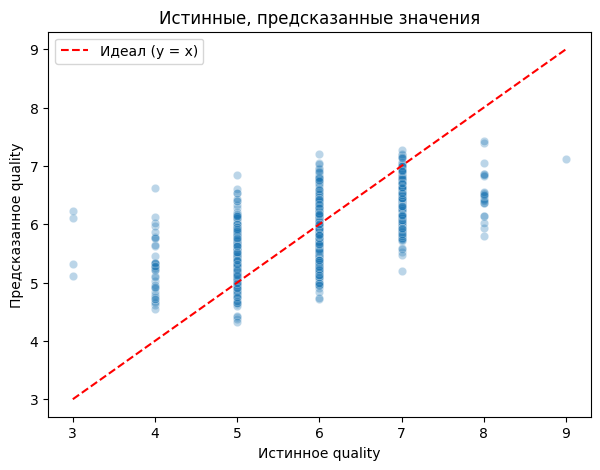

In [263]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Идеал (y = x)')
plt.xlabel('Истинное quality')
plt.ylabel('Предсказанное quality')
plt.title('Истинные, предсказанные значения')
plt.legend()
plt.show()

In [265]:
df_results.groupby('y_true')['error'].agg(['count', 'mean', 'median'])

,count,mean,median
y_true,,,
3,4,2.692500,2.710
4,38,1.262632,1.260
5,348,0.448333,0.355
6,458,0.370022,0.305
7,190,0.624421,0.600
8,25,1.469600,1.500
9,1,1.890000,1.890
